In [1]:
from langgraph.graph import StateGraph,START,END
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from dotenv import load_dotenv
from typing import TypedDict

/Users/abn904/Library/Python/3.13/lib/python/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
/Users/abn904/Library/Python/3.13/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

llm = HuggingFaceEndpoint(
    repo_id="openai/gpt-oss-20b",
    task = 'text-generation'
)

model = ChatHuggingFace(llm = llm)

In [3]:
class BattingScore(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int

    bpb: float
    strike_rate: float
    boundary_run_percentage: float
    summary:str

In [4]:
def calculate_sr(state: BattingScore) -> BattingScore:
    x = (state['runs']/state['balls'])*100

    return {'strike_rate': x}

In [5]:
def calculate_bpb(state: BattingScore) -> BattingScore:
    x = state['balls']/(state['fours'] + state['sixes'])

    return {'bpb': x}

In [6]:
def calculate_brp(state: BattingScore) -> BattingScore:
    x = ((state['fours'] * 4 + state['sixes'] * 6)/state['runs'])*100

    return {'boundary_run_percentage': x}

In [7]:
def calculate_summary(state:BattingScore) -> BattingScore:

    x = f"""
        Strike Rate : {state['strike_rate']},
        Balls Per Boundary : {state['bpb']},
        Runs scored via boundary % : {state['boundary_run_percentage']}
"""
    state['summary'] = x

    return state

In [8]:
graph = StateGraph(BattingScore)

graph.add_node("calculate_sr",calculate_sr)
graph.add_node("calculate_bpb",calculate_bpb)
graph.add_node("calculate_brp",calculate_brp)
graph.add_node("calculate_summary",calculate_summary)

In [9]:
graph.add_edge(START,"calculate_sr")
graph.add_edge(START,"calculate_bpb")
graph.add_edge(START,"calculate_brp")

graph.add_edge("calculate_sr","calculate_summary")
graph.add_edge("calculate_bpb","calculate_summary")
graph.add_edge("calculate_brp","calculate_summary")

graph.add_edge("calculate_summary",END)

In [10]:
workflow = graph.compile()

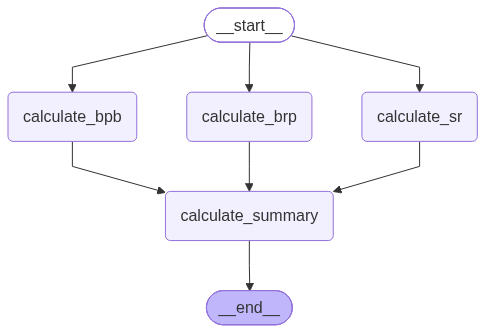

In [11]:
workflow

In [ ]:
answer = workflow.invoke({
    "runs": 100 ,
    "balls": 50,
    "fours": 5,
    "sixes": 5
})

InvalidUpdateError: At key 'runs': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_CONCURRENT_GRAPH_UPDATE